In [ ]:
# !pip install numpy
# !pip install pandas
# !pip install matplotlib
# !pip install scipy
# !pip install scikit-learn

In [ ]:
import sys, platform, importlib.metadata
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

plt.rcParams.update({'figure.figsize': (9, 4), 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 11})

In [ ]:
print('Python:', platform.python_version())
print({p: importlib.metadata.version(p) for p in ['numpy','pandas','matplotlib','scikit-learn','scipy']})


Python: 3.13.16
Still running...
{'numpy': '2.1.3', 'pandas': '2.2.3', 'matplotlib': '3.10.0', 'scikit-learn': '1.6.1', 'scipy': '1.16.3'}


In [ ]:
from pandas import read_csv

df = read_csv("data/tips.csv")
df.index.name = "row_id"
original = df.copy(deep=True)

print('>> Rows:', len(df), '| Missing values:', int(df.isna().sum().sum()))
print("\n\n")
df.head(5)

>> Rows: 244 | Missing values: 0





,total_bill,tip,sex,smoker,day,time,size
row_id,,,,,,,
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [ ]:
train, test = train_test_split(df, test_size=0.25, random_state=42)
train, test = train.copy(), test.copy()
print('Training rows:', len(train), '| Test rows:', len(test))
display(train[['total_bill','tip','size','day','time']].head())

Training rows: 183 | Test rows: 61


,total_bill,tip,size,day,time
row_id,,,,,
115,17.31,3.50,2,Sun,Dinner
181,23.33,5.65,2,Sun,Dinner
225,16.27,2.50,2,Fri,Lunch
68,20.23,2.01,2,Sat,Dinner
104,20.92,4.08,2,Sat,Dinner


In [ ]:
244*(1-0.25)

183.0

# Notice the unusual values

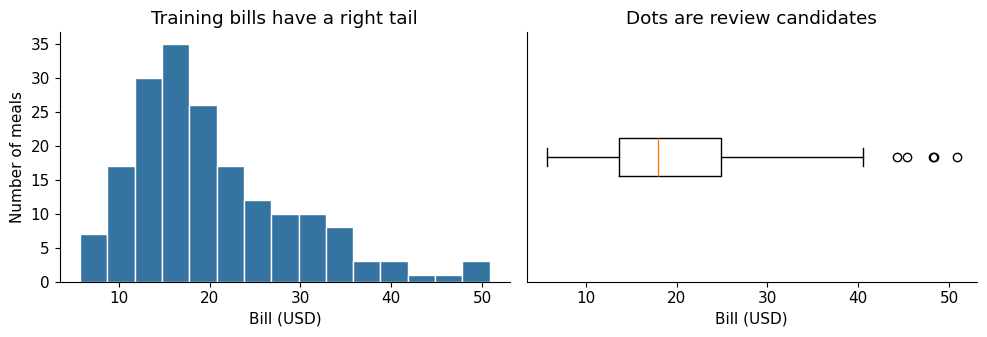

count    183.00
mean      20.27
std        8.87
min        5.75
25%       13.66
50%       17.92
75%       24.86
max       50.81


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].hist(train['total_bill'], bins=15, color='#3574a1', edgecolor='white')
ax[0].set(xlabel='Bill (USD)', ylabel='Number of meals', title='Training bills have a right tail')

ax[1].boxplot(train['total_bill'], orientation='horizontal', whis=1.5)
ax[1].set(xlabel='Bill (USD)', yticks=[], title='Dots are review candidates')

plt.tight_layout(); plt.show()

print(train['total_bill'].describe().round(2).to_string())

# Detect with transparent rule

In [ ]:
# Manual computation of quartiles
def quartiles(values):
    values = sorted(values)
    if not values:
        raise ValueError("Input cannot be empty")

    def percentile(p):
        position = (len(values) - 1) * p
        left = int(position)
        right = min(left + 1, len(values) - 1)
        fraction = position - left
        return values[left] + fraction * (values[right] - values[left])

    return percentile(0.25), percentile(0.50), percentile(0.75)


q1, q2, q3 = quartiles(train["total_bill"])
print(q1, q2, q3)  # 12.0 12.5 14.5

13.66 17.92 24.855


In [ ]:
q1, q3 = train['total_bill'].quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr

def flag_bill(frame):
    return (frame['total_bill'] < lower) | (frame['total_bill'] > upper)

train_flag, test_flag = flag_bill(train), flag_bill(test)

print(f'Q1={q1:.4f}, Q3={q3:.4f}, IQR={iqr:.4f}')
print(f'Fences: [{lower:.4f}, {upper:.4f}] USD')
print(f'Train flagged: {train_flag.sum()}/{len(train)}')
print(f'Held-out flagged with SAME limits: {test_flag.sum()}/{len(test)}')

Q1=13.6600, Q3=24.8550, IQR=11.1950
Fences: [-3.1325, 41.6475] USD
Train flagged: 5/183
Held-out flagged with SAME limits: 2/61


In [ ]:
train_flag

,total_bill
row_id,
115,False
181,False
225,False
68,False
104,False
...,...
106,False
14,False
92,False


In [ ]:
# Find the indices of outliers
train_outlier_indices = train.index[train_flag].tolist()
test_outlier_indices = test.index[test_flag].tolist()

print("Train outlier indices:", train_outlier_indices)
print("Test outlier indices:", test_outlier_indices)

Train outlier indices: [170, 182, 59, 212, 102]
Test outlier indices: [156, 197]


# Investigate context before acting

,total_bill,tip,size,day,time,bill_per_person
row_id,,,,,,
170,50.81,10.00,3,Sat,Dinner,16.94
212,48.33,9.00,4,Sat,Dinner,12.08
59,48.27,6.73,4,Sat,Dinner,12.07
182,45.35,3.50,3,Sun,Dinner,15.12
102,44.30,2.50,3,Sat,Dinner,14.77


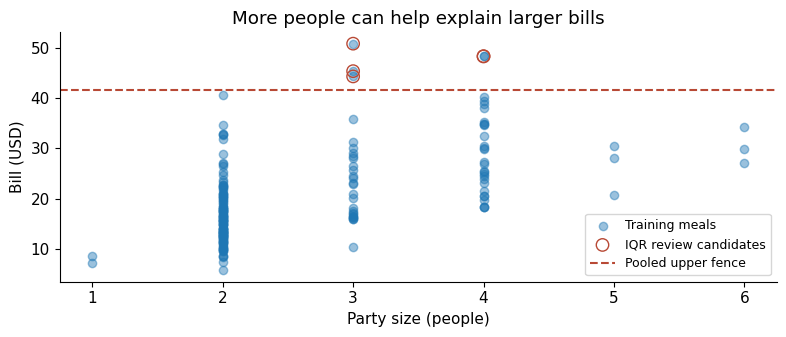

      count  median    max
size                      
1         2    7.92   8.58
2       118   15.61  40.55
3        28   22.96  50.81
4        29   27.20  48.33
5         3   28.15  30.46
6         3   29.80  34.30


In [ ]:
review = train.loc[train_flag, ['total_bill','tip','size','day','time']].copy()
review['bill_per_person'] = review['total_bill'] / review['size']

display(review.sort_values('total_bill', ascending=False).round(2))

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.scatter(train['size'], train['total_bill'], alpha=.45, label='Training meals')
ax.scatter(train.loc[train_flag,'size'], train.loc[train_flag,'total_bill'],
           color='#b84935', s=80, facecolors='none', label='IQR review candidates')

ax.axhline(upper, color='#b84935', ls='--', label='Pooled upper fence')
ax.set(xlabel='Party size (people)', ylabel='Bill (USD)', title='More people can help explain larger bills')
ax.legend(fontsize=9); plt.tight_layout(); plt.show()
print(train.groupby('size')['total_bill'].agg(['count','median','max']).round(2).to_string())

# Compare treatment choices

,Treatment,Rows,Mean,Median
0,Original,183,20.27,17.92
1,Remove,178,19.51,17.69
2,Cap,183,20.11,17.92


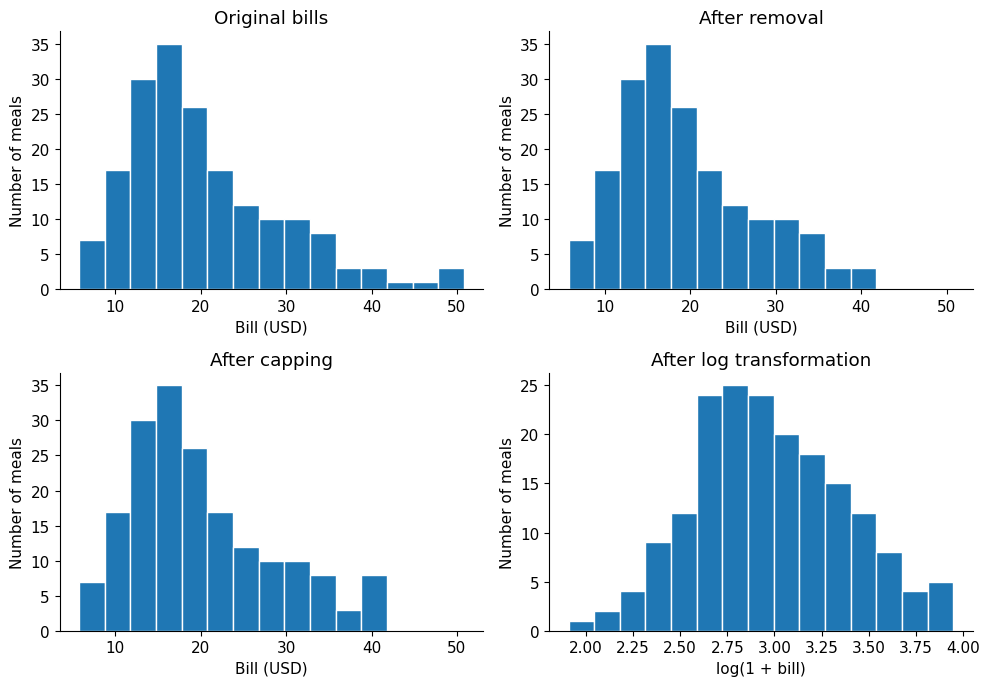

In [ ]:
# 1. Create separate versions of the bill column
bills = train["total_bill"]

removed_bills = bills[~train_flag]               # Remove flagged bills
capped_bills = bills.clip(lower, upper)          # Limit extreme values
log_bills = np.log1p(bills)                      # Apply log(1 + bill)


# 2. Compare basic statistics
comparison = pd.DataFrame({
    "Treatment": ["Original", "Remove", "Cap"],
    "Rows": [len(bills), len(removed_bills), len(capped_bills)],
    "Mean": [bills.mean(), removed_bills.mean(), capped_bills.mean()],
    "Median": [bills.median(), removed_bills.median(), capped_bills.median()]
})

display(comparison.round(2))


# 3. Compare distributions
# Use the same intervals for all plots measured in dollars.
bins = np.linspace(bills.min(), bills.max(), 16)

plt.figure(figsize=(10, 7))

plt.subplot(2, 2, 1)
plt.hist(bills, bins=bins, edgecolor="white")
plt.title("Original bills")
plt.xlabel("Bill (USD)")
plt.ylabel("Number of meals")

plt.subplot(2, 2, 2)
plt.hist(removed_bills, bins=bins, edgecolor="white")
plt.title("After removal")
plt.xlabel("Bill (USD)")
plt.ylabel("Number of meals")

plt.subplot(2, 2, 3)
plt.hist(capped_bills, bins=bins, edgecolor="white")
plt.title("After capping")
plt.xlabel("Bill (USD)")
plt.ylabel("Number of meals")

plt.subplot(2, 2, 4)
plt.hist(log_bills, bins=15, edgecolor="white")
plt.title("After log transformation")
plt.xlabel("log(1 + bill)")
plt.ylabel("Number of meals")

plt.tight_layout()
plt.show()